<a href="https://colab.research.google.com/github/Ossel14/atelier1-deeplearning/blob/main/notebooks/01_regression_nyse.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Atelier 1 — Deep Learning avec PyTorch

## Partie 1 : Régression — Dataset NYSE

### Objectif
Construire un réseau de neurones profond (MLP) capable de prédire
le prix de clôture d'une action à partir de données historiques.

### Étape 1 : Chargement et exploration du dataset

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch

print("PyTorch version :", torch.__version__)
print("GPU disponible :", torch.cuda.is_available())

PyTorch version : 2.11.0+cu130
GPU disponible : True


In [3]:
import kagglehub
import pandas as pd
from pathlib import Path

# Télécharger le fichier directement depuis Kaggle
file_path = kagglehub.dataset_download(
    "dgawlik/nyse",
    path="prices-split-adjusted.csv"
)

# Charger les données
df = pd.read_csv(file_path)

print("Dimensions du dataset :", df.shape)
print("\nColonnes :", df.columns.tolist())

display(df.head())

100%|██████████| 15.6M/15.6M [00:01<00:00, 8.35MB/s]

Extracting zip of prices-split-adjusted.csv...


Dimensions du dataset : (851264, 7)

Colonnes : ['date', 'symbol', 'open', 'close', 'low', 'high', 'volume']


,date,symbol,open,close,low,high,volume
0,2016-01-05,WLTW,123.430000,125.839996,122.309998,126.250000,2163600.0
1,2016-01-06,WLTW,125.239998,119.980003,119.940002,125.540001,2386400.0
2,2016-01-07,WLTW,116.379997,114.949997,114.930000,119.739998,2489500.0
3,2016-01-08,WLTW,115.480003,116.620003,113.500000,117.440002,2006300.0
4,2016-01-11,WLTW,117.010002,114.970001,114.089996,117.330002,1408600.0


In [4]:
print("Informations générales :")
df.info()

print("\nStatistiques descriptives :")
display(df.describe())

Informations générales :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 851264 entries, 0 to 851263
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   date    851264 non-null  object 
 1   symbol  851264 non-null  object 
 2   open    851264 non-null  float64
 3   close   851264 non-null  float64
 4   low     851264 non-null  float64
 5   high    851264 non-null  float64
 6   volume  851264 non-null  float64
dtypes: float64(5), object(2)
memory usage: 45.5+ MB

Statistiques descriptives :


,open,close,low,high,volume
count,851264.000000,851264.000000,851264.000000,851264.000000,8.512640e+05
mean,64.993618,65.011913,64.336541,65.639748,5.415113e+06
std,75.203893,75.201216,74.459518,75.906861,1.249468e+07
min,1.660000,1.590000,1.500000,1.810000,0.000000e+00
25%,31.270000,31.292776,30.940001,31.620001,1.221500e+06
50%,48.459999,48.480000,47.970001,48.959999,2.476250e+06
75%,75.120003,75.139999,74.400002,75.849998,5.222500e+06
max,1584.439941,1578.130005,1549.939941,1600.930054,8.596434e+08


## 2. Analyse exploratoire des données (EDA)

L'objectif de cette étape est de comprendre la structure du dataset NYSE,
d'identifier les types de variables, de détecter les valeurs manquantes
et d'étudier les caractéristiques des données financières avant
la construction du modèle de régression.

In [5]:
# Dimensions du dataset
print("Dimensions :", df.shape)

# Types des variables
print("\nTypes des variables :")
print(df.dtypes)

# Nombre d'entreprises différentes
print("\nNombre d'entreprises :", df["symbol"].nunique())

# Période couverte
df["date"] = pd.to_datetime(df["date"])

print("\nDate minimale :", df["date"].min())
print("Date maximale :", df["date"].max())

# Aperçu du dataset
display(df.head())

Dimensions : (851264, 7)

Types des variables :
date       object
symbol     object
open      float64
close     float64
low       float64
high      float64
volume    float64
dtype: object

Nombre d'entreprises : 501

Date minimale : 2010-01-04 00:00:00
Date maximale : 2016-12-30 00:00:00


,date,symbol,open,close,low,high,volume
0,2016-01-05,WLTW,123.430000,125.839996,122.309998,126.250000,2163600.0
1,2016-01-06,WLTW,125.239998,119.980003,119.940002,125.540001,2386400.0
2,2016-01-07,WLTW,116.379997,114.949997,114.930000,119.739998,2489500.0
3,2016-01-08,WLTW,115.480003,116.620003,113.500000,117.440002,2006300.0
4,2016-01-11,WLTW,117.010002,114.970001,114.089996,117.330002,1408600.0


In [6]:
# Valeurs manquantes
missing_values = df.isnull().sum()

print("Valeurs manquantes par colonne :")
display(missing_values)

# Pourcentage de valeurs manquantes
missing_percent = (df.isnull().sum() / len(df)) * 100

print("\nPourcentage de valeurs manquantes :")
display(missing_percent)

# Détection des doublons
print("\nNombre de lignes dupliquées :", df.duplicated().sum())

# Détection des doublons par entreprise et date
print(
    "Doublons (date, symbol) :",
    df.duplicated(subset=["date", "symbol"]).sum()
)

Valeurs manquantes par colonne :


,0
date,0
symbol,0
open,0
close,0
low,0
high,0
volume,0



Pourcentage de valeurs manquantes :


,0
date,0.0
symbol,0.0
open,0.0
close,0.0
low,0.0
high,0.0
volume,0.0



Nombre de lignes dupliquées : 0
Doublons (date, symbol) : 0


,date,open,close,low,high,volume
count,851264,851264.000000,851264.000000,851264.000000,851264.000000,8.512640e+05
mean,2013-07-21 02:56:29.294037760,64.993618,65.011913,64.336541,65.639748,5.415113e+06
min,2010-01-04 00:00:00,1.660000,1.590000,1.500000,1.810000,0.000000e+00
25%,2011-10-19 00:00:00,31.270000,31.292776,30.940001,31.620001,1.221500e+06
50%,2013-08-02 00:00:00,48.459999,48.480000,47.970001,48.959999,2.476250e+06
75%,2015-04-24 00:00:00,75.120003,75.139999,74.400002,75.849998,5.222500e+06
max,2016-12-30 00:00:00,1584.439941,1578.130005,1549.939941,1600.930054,8.596434e+08
std,NaN,75.203893,75.201216,74.459518,75.906861,1.249468e+07


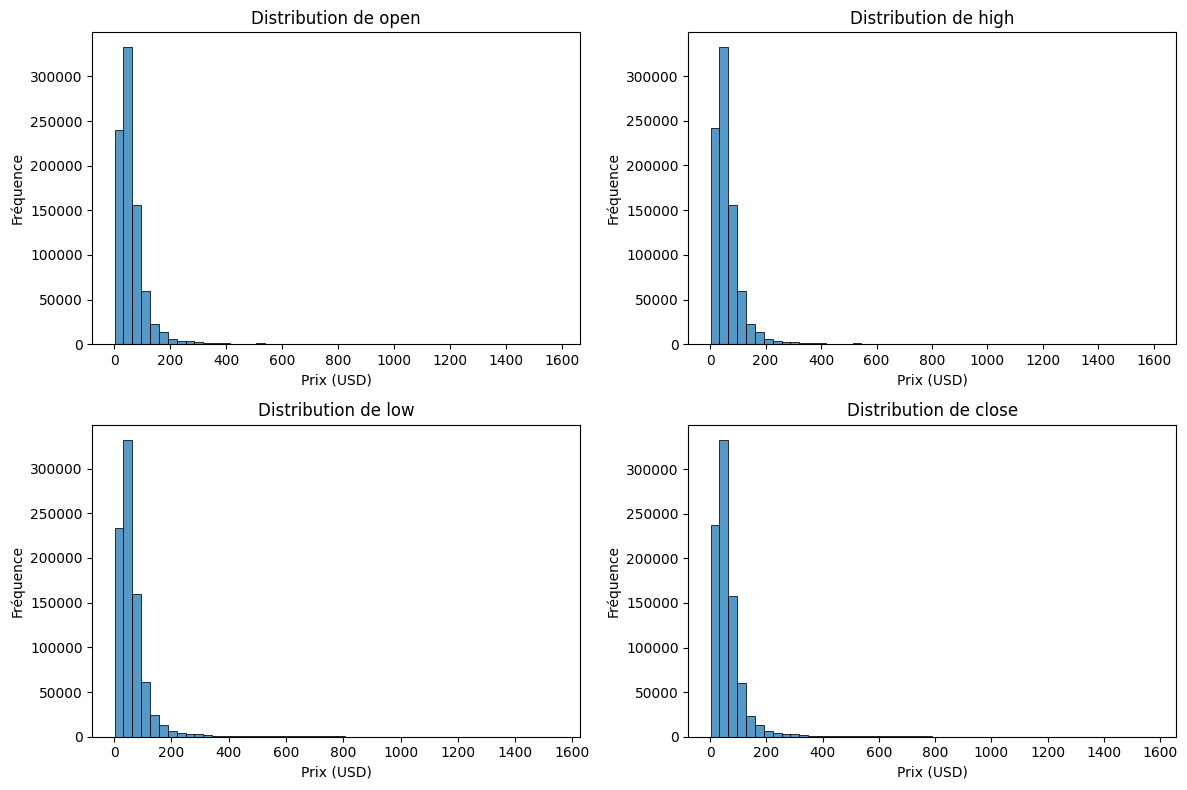

In [7]:
# Statistiques descriptives
display(df.describe())

# Visualisation des distributions
price_columns = ["open", "high", "low", "close"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.flatten(), price_columns):
    sns.histplot(df[col].dropna(), bins=50, ax=ax)
    ax.set_title(f"Distribution de {col}")
    ax.set_xlabel("Prix (USD)")
    ax.set_ylabel("Fréquence")

plt.tight_layout()
plt.show()


### 3.1 Analyse des corrélations

La matrice de corrélation permet d'étudier les relations linéaires
entre les variables numériques.

Une corrélation proche de 1 indique une forte relation positive,
tandis qu'une corrélation proche de 0 indique une faible relation linéaire.

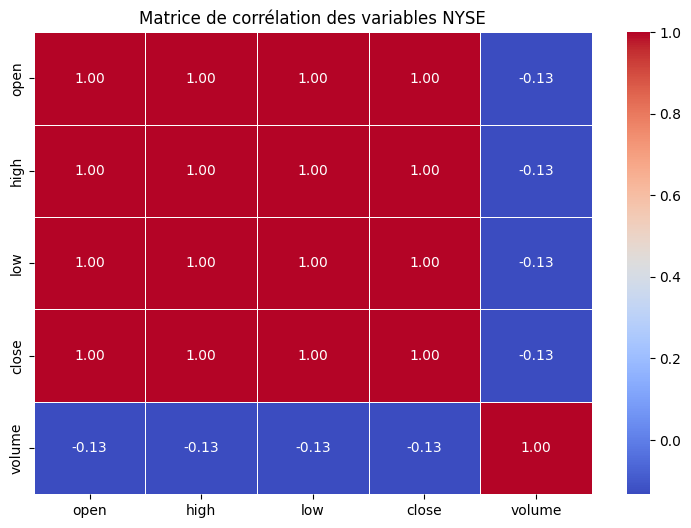

In [8]:
# Sélectionner les variables numériques
numeric_cols = ["open", "high", "low", "close", "volume"]

# Calculer la matrice de corrélation
corr_matrix = df[numeric_cols].corr()

# Visualiser la matrice
plt.figure(figsize=(9, 6))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Matrice de corrélation des variables NYSE")
plt.show()

Nombre d'observations Apple : 1762


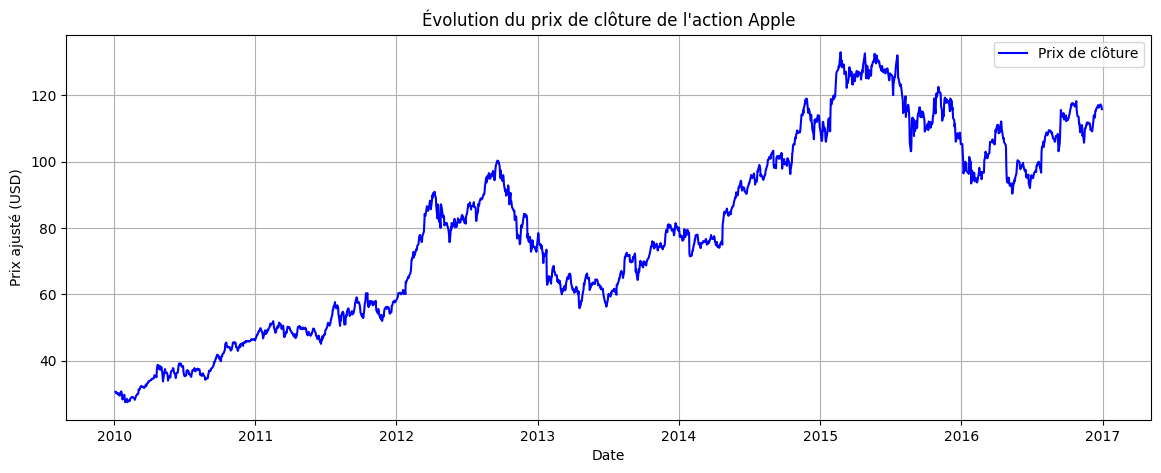

In [9]:
# Filtrer les données de l'entreprise Apple
df_apple = df[df["symbol"] == "AAPL"].copy()

# Trier chronologiquement
df_apple = df_apple.sort_values("date")

print("Nombre d'observations Apple :", len(df_apple))

# Visualisation
plt.figure(figsize=(14, 5))

plt.plot(
    df_apple["date"],
    df_apple["close"],
    label="Prix de clôture",
    color="blue"
)

plt.title("Évolution du prix de clôture de l'action Apple")
plt.xlabel("Date")
plt.ylabel("Prix ajusté (USD)")
plt.legend()
plt.grid(True)
plt.show()

## 4. Préparation des données pour la régression

Nous cherchons à prédire le prix de clôture ajusté de l'action
Apple au prochain jour de négociation.

Variables explicatives (X) :
- open
- high
- low
- close
- volume

Variable cible (y) :
- close_next_day

La variable cible est obtenue en décalant la colonne `close`
d'une observation vers le futur.

Afin d'éviter les fuites de données temporelles, nous utiliserons
une séparation chronologique pour l'entraînement et le test.

In [10]:
# Copier les données Apple
data = df_apple.copy()

# Trier par date
data = data.sort_values("date").reset_index(drop=True)

# Créer le prix de clôture du prochain jour de négociation
data["close_next_day"] = data["close"].shift(-1)

# Supprimer la dernière ligne (cible inconnue)
data = data.dropna(subset=["close_next_day"])

# Définir les variables d'entrée et la cible
features = ["open", "high", "low", "close", "volume"]

X = data[features]
y = data["close_next_day"]

print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

display(data[
    ["date", "close", "close_next_day"]
].head(10))

Dimensions de X : (1761, 5)
Dimensions de y : (1761,)


,date,close,close_next_day
0,2010-01-04,30.572857,30.625713
1,2010-01-05,30.625713,30.138571
2,2010-01-06,30.138571,30.082857
3,2010-01-07,30.082857,30.282858
4,2010-01-08,30.282858,30.015715
5,2010-01-11,30.015715,29.674286
6,2010-01-12,29.674286,30.092857
7,2010-01-13,30.092857,29.918571
8,2010-01-14,29.918571,29.418571
9,2010-01-15,29.418571,30.719999


## 5. Séparation des données et standardisation

Le dataset est divisé chronologiquement en trois ensembles :
- 70 % pour l'entraînement
- 15 % pour la validation
- 15 % pour le test

Cette approche respecte la nature temporelle des données
boursières et évite d'utiliser des observations futures
pour prédire le passé.

In [11]:
# Nombre total d'observations
n = len(data)

# Indices de séparation
train_end = int(n * 0.70)
val_end = int(n * 0.85)

# Séparation chronologique
X_train = X.iloc[:train_end]
X_val = X.iloc[train_end:val_end]
X_test = X.iloc[val_end:]

y_train = y.iloc[:train_end]
y_val = y.iloc[train_end:val_end]
y_test = y.iloc[val_end:]

# Vérification des dimensions
print("Train :", X_train.shape, y_train.shape)
print("Validation :", X_val.shape, y_val.shape)
print("Test :", X_test.shape, y_test.shape)

# Vérification des périodes
print("\nPériode Train :",
      data["date"].iloc[0],
      "→", data["date"].iloc[train_end-1])

print("Période Validation :",
      data["date"].iloc[train_end],
      "→", data["date"].iloc[val_end-1])

print("Période Test :",
      data["date"].iloc[val_end],
      "→", data["date"].iloc[-1])

Train : (1232, 5) (1232,)
Validation : (264, 5) (264,)
Test : (265, 5) (265,)

Période Train : 2010-01-04 00:00:00 → 2014-11-21 00:00:00
Période Validation : 2014-11-24 00:00:00 → 2015-12-10 00:00:00
Période Test : 2015-12-11 00:00:00 → 2016-12-29 00:00:00


In [12]:
from sklearn.preprocessing import StandardScaler

# Initialiser le scaler
scaler_X = StandardScaler()

# Apprentissage uniquement sur Train
X_train_scaled = scaler_X.fit_transform(X_train)

# Application sur Validation et Test
X_val_scaled = scaler_X.transform(X_val)
X_test_scaled = scaler_X.transform(X_test)

# Vérification
print("Moyenne des variables Train standardisées :")
print(X_train_scaled.mean(axis=0).round(4))

print("\nÉcart-type des variables Train standardisées :")
print(X_train_scaled.std(axis=0).round(4))

Moyenne des variables Train standardisées :
[ 0. -0. -0.  0.  0.]

Écart-type des variables Train standardisées :
[1. 1. 1. 1. 1.]


In [13]:
# Initialiser le scaler pour la cible
scaler_y = StandardScaler()

y_train_scaled = scaler_y.fit_transform(
    y_train.to_numpy().reshape(-1, 1)
)

y_val_scaled = scaler_y.transform(
    y_val.to_numpy().reshape(-1, 1)
)

y_test_scaled = scaler_y.transform(
    y_test.to_numpy().reshape(-1, 1)
)

print("Exemple de prix original :", y_train.iloc[0])
print("Prix standardisé :", y_train_scaled[0][0])

Exemple de prix original : 30.6257132857
Prix standardisé : -1.669184711273078


## 6. Construction du modèle MLP avec PyTorch

Nous allons construire un réseau de neurones profond pour prédire
le prix de clôture de l'action Apple au prochain jour de négociation.

Architecture :
- Couche d'entrée : 5 neurones
- Première couche cachée : 64 neurones, activation ReLU
- Deuxième couche cachée : 32 neurones, activation ReLU
- Couche de sortie : 1 neurone (régression)

Le modèle sera entraîné avec l'optimiseur Adam et la fonction de perte MSE.

In [14]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Reproductibilité
torch.manual_seed(42)
np.random.seed(42)

# GPU si disponible
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device utilisé :", device)

# Conversion des données en tenseurs Float32
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_scaled, dtype=torch.float32)

X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val_scaled, dtype=torch.float32)

X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test_scaled, dtype=torch.float32)

# Création des datasets
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

# DataLoader pour l'entraînement
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

print("Train batches :", len(train_loader))
print("Validation batches :", len(val_loader))
print("Test batches :", len(test_loader))

Device utilisé : cuda
Train batches : 39
Validation batches : 9
Test batches : 9


In [15]:
class MLPRegression(nn.Module):

    def __init__(self):
        super(MLPRegression, self).__init__()

        self.network = nn.Sequential(
            nn.Linear(5, 64),
            nn.ReLU(),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x)


# Initialiser le modèle
model = MLPRegression().to(device)

# Afficher l'architecture
print(model)

# Nombre total de paramètres
total_params = sum(p.numel() for p in model.parameters())

print("\nNombre total de paramètres :", total_params)

MLPRegression(
  (network): Sequential(
    (0): Linear(in_features=5, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)

Nombre total de paramètres : 2497


In [16]:
# Fonction de perte pour la régression
criterion = nn.MSELoss()

# Optimiseur Adam
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

# Nombre d'époques
epochs = 100

print("Loss function :", criterion)
print("Optimizer :", optimizer.__class__.__name__)
print("Learning rate :", optimizer.param_groups[0]["lr"])
print("Epochs :", epochs)

Loss function : MSELoss()
Optimizer : Adam
Learning rate : 0.001
Epochs : 100


## 7. Entraînement du modèle MLP

Le modèle est entraîné pendant 100 époques avec l'optimiseur
Adam et un taux d'apprentissage de 0.001.

La fonction de perte MSE mesure l'écart quadratique entre les
prix prédits et les valeurs réelles standardisées.

Nous suivons les pertes d'entraînement et de validation afin
d'analyser la convergence du modèle et de détecter
un éventuel surapprentissage.

In [17]:
# Historique des pertes
train_losses = []
val_losses = []

for epoch in range(epochs):

    # ===== PHASE TRAINING =====
    model.train()
    running_train_loss = 0.0

    for X_batch, y_batch in train_loader:

        # Transfert vers GPU
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        # Réinitialiser les gradients
        optimizer.zero_grad()

        # Forward propagation
        predictions = model(X_batch)

        # Calcul de la perte
        loss = criterion(predictions, y_batch)

        # Backpropagation
        loss.backward()

        # Mise à jour des poids
        optimizer.step()

        # Accumuler la perte
        running_train_loss += loss.item() * X_batch.size(0)

    # Perte moyenne de l'époque
    train_loss = running_train_loss / len(train_dataset)
    train_losses.append(train_loss)

    # ===== PHASE VALIDATION =====
    model.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for X_batch, y_batch in val_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            predictions = model(X_batch)
            loss = criterion(predictions, y_batch)

            running_val_loss += loss.item() * X_batch.size(0)

    val_loss = running_val_loss / len(val_dataset)
    val_losses.append(val_loss)

    # Affichage tous les 10 epochs
    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Train Loss: {train_loss:.6f} | "
            f"Val Loss: {val_loss:.6f}"
        )

Epoch [10/100] Train Loss: 0.003581 | Val Loss: 0.010345
Epoch [20/100] Train Loss: 0.003508 | Val Loss: 0.010120
Epoch [30/100] Train Loss: 0.003246 | Val Loss: 0.011256
Epoch [40/100] Train Loss: 0.003307 | Val Loss: 0.014656
Epoch [50/100] Train Loss: 0.003111 | Val Loss: 0.010239
Epoch [60/100] Train Loss: 0.003100 | Val Loss: 0.024066
Epoch [70/100] Train Loss: 0.003050 | Val Loss: 0.009894
Epoch [80/100] Train Loss: 0.002983 | Val Loss: 0.009999
Epoch [90/100] Train Loss: 0.003297 | Val Loss: 0.016680
Epoch [100/100] Train Loss: 0.002948 | Val Loss: 0.011261


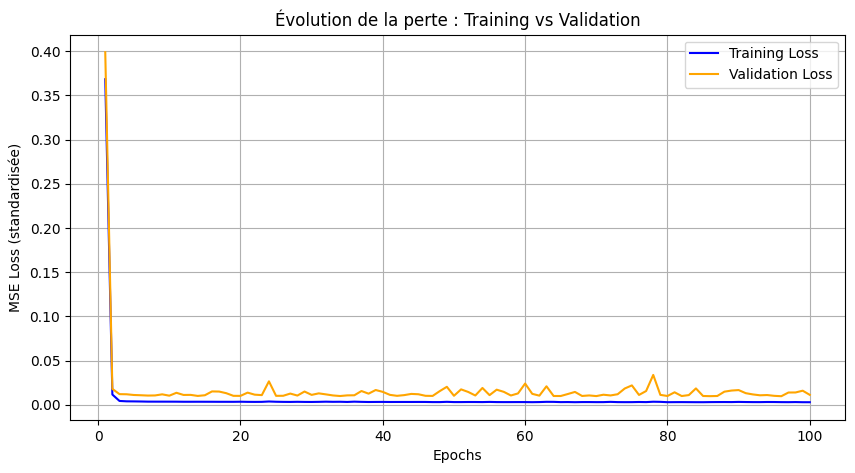

Meilleure époque : 96
Meilleure Validation Loss : 0.009750257556637129
Dernière Training Loss : 0.0029478543286828637
Dernière Validation Loss : 0.011261090523365772


In [18]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, epochs + 1),
    train_losses,
    label="Training Loss",
    color="blue"
)

plt.plot(
    range(1, epochs + 1),
    val_losses,
    label="Validation Loss",
    color="orange"
)

plt.xlabel("Epochs")
plt.ylabel("MSE Loss (standardisée)")
plt.title("Évolution de la perte : Training vs Validation")
plt.legend()
plt.grid(True)

plt.show()

# Meilleure époque sur Validation
best_epoch = np.argmin(val_losses) + 1

print("Meilleure époque :", best_epoch)
print("Meilleure Validation Loss :", min(val_losses))
print("Dernière Training Loss :", train_losses[-1])
print("Dernière Validation Loss :", val_losses[-1])

## 8. Évaluation du modèle de régression

Les performances du modèle MLP sont évaluées sur les ensembles
d'entraînement et de test à l'aide des métriques MAE, MSE,
RMSE et R².

Les prédictions sont converties dans leur unité d'origine (USD).

Nous comparons également le modèle à une méthode naïve :
le prix prédit pour le prochain jour est égal au prix de
clôture du jour actuel.

In [19]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Passer en mode évaluation
model.eval()

def predict_mlp(X_tensor):
    with torch.no_grad():
        predictions = model(X_tensor.to(device))

    predictions = predictions.cpu().numpy()

    return scaler_y.inverse_transform(predictions).flatten()


# Prédictions Train et Test
y_pred_train = predict_mlp(X_train_tensor)
y_pred_test = predict_mlp(X_test_tensor)


# Fonction pour calculer les métriques
def evaluate_regression(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mean_squared_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }


# Métriques du MLP
train_metrics = evaluate_regression(y_train, y_pred_train)
test_metrics = evaluate_regression(y_test, y_pred_test)

# Baseline naïve : Close(t+1) = Close(t)
naive_pred_test = X_test["close"].to_numpy()

naive_metrics = evaluate_regression(
    y_test,
    naive_pred_test
)

# Tableau comparatif
results = pd.DataFrame({
    "MLP Train": train_metrics,
    "MLP Test": test_metrics,
    "Naive Test": naive_metrics
}).T

display(results.round(4))

,MAE,MSE,RMSE,R2
MLP Train,0.7801,1.2257,1.1071,0.9972
MLP Test,1.1337,2.4211,1.5560,0.9569
Naive Test,1.0635,2.2629,1.5043,0.9597


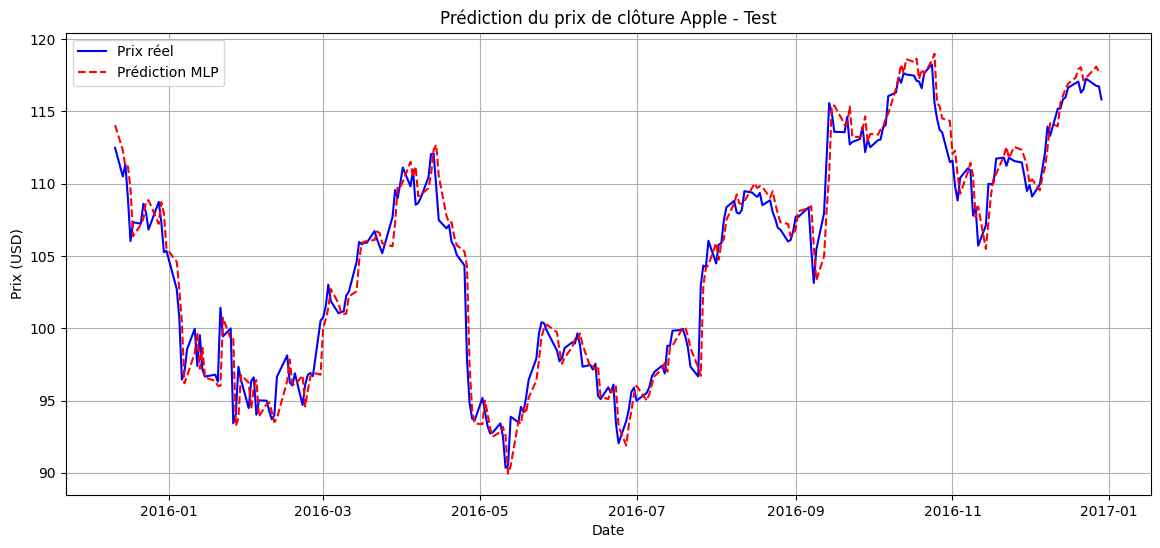

In [20]:
# Dates correspondant au jeu de test
test_dates = data["date"].iloc[val_end:]

plt.figure(figsize=(14, 6))

plt.plot(
    test_dates,
    y_test,
    label="Prix réel",
    color="blue"
)

plt.plot(
    test_dates,
    y_pred_test,
    label="Prédiction MLP",
    color="red",
    linestyle="--"
)

plt.title("Prédiction du prix de clôture Apple - Test")
plt.xlabel("Date")
plt.ylabel("Prix (USD)")
plt.legend()
plt.grid(True)
plt.show()

## 9. Analyse de la généralisation

Cette étape consiste à comparer les performances du modèle
sur les ensembles Train, Validation et Test.

L'objectif est d'étudier sa capacité de généralisation,
de détecter un éventuel surapprentissage et d'évaluer
ses performances par rapport à un modèle naïf.

Les résultats obtenus sur Test seront conservés comme
référence initiale, sans servir au choix des hyperparamètres.

In [21]:
# Prédictions sur Validation
y_pred_val = predict_mlp(X_val_tensor)

# Construire le tableau des performances
comparison = pd.DataFrame({
    "MLP Train": evaluate_regression(y_train, y_pred_train),
    "MLP Validation": evaluate_regression(y_val, y_pred_val),
    "MLP Test": evaluate_regression(y_test, y_pred_test),

    "Naive Train": evaluate_regression(
        y_train, X_train["close"]
    ),
    "Naive Validation": evaluate_regression(
        y_val, X_val["close"]
    ),
    "Naive Test": evaluate_regression(
        y_test, X_test["close"]
    )
}).T

display(comparison.round(4))

,MAE,MSE,RMSE,R2
MLP Train,0.7801,1.2257,1.1071,0.9972
MLP Validation,1.7126,4.8568,2.2038,0.9110
MLP Test,1.1337,2.4211,1.5560,0.9569
Naive Train,0.7782,1.2569,1.1211,0.9971
Naive Validation,1.4899,3.8281,1.9566,0.9298
Naive Test,1.0635,2.2629,1.5043,0.9597


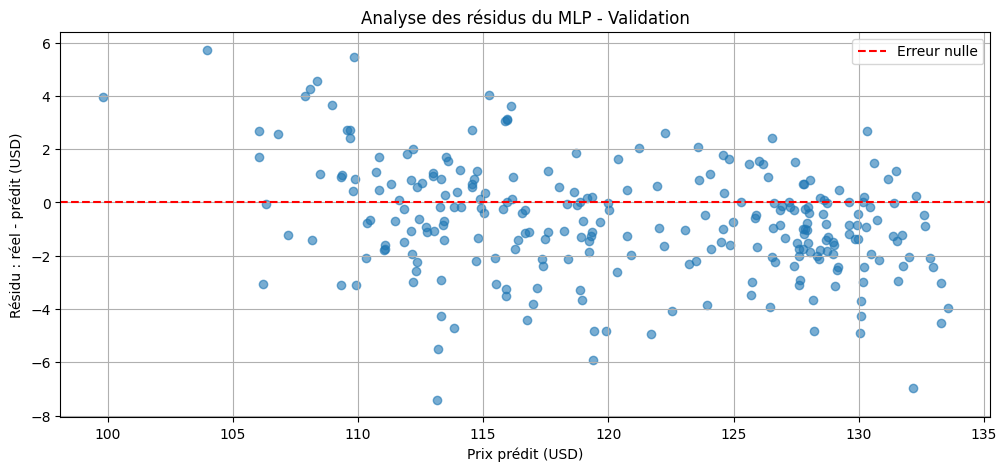

In [22]:
# Résidus sur l'ensemble de validation
residuals_val = y_val.to_numpy() - y_pred_val

plt.figure(figsize=(12, 5))

plt.scatter(
    y_pred_val,
    residuals_val,
    alpha=0.6
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Erreur nulle"
)

plt.xlabel("Prix prédit (USD)")
plt.ylabel("Résidu : réel - prédit (USD)")
plt.title("Analyse des résidus du MLP - Validation")
plt.legend()
plt.grid(True)
plt.show()

## 10. Optimisation des hyperparamètres avec GridSearchCV

Nous utilisons GridSearchCV de scikit-learn pour rechercher
les meilleurs hyperparamètres de notre réseau MLP PyTorch.

La bibliothèque Skorch permet d'intégrer un modèle PyTorch
dans l'écosystème scikit-learn.

Une validation croisée temporelle (TimeSeriesSplit) est utilisée
afin de respecter l'ordre chronologique des observations.

In [23]:
!pip install -q skorch

In [24]:
from skorch import NeuralNetRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
import torch.optim as optim

class TunableMLP(nn.Module):

    def __init__(self, hidden1=64, hidden2=32):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(5, hidden1),
            nn.ReLU(),
            nn.Linear(hidden1, hidden2),
            nn.ReLU(),
            nn.Linear(hidden2, 1)
        )

    def forward(self, x):
        return self.network(x)


# Vérifier l'architecture
test_model = TunableMLP(hidden1=128, hidden2=64)
print(test_model)

TunableMLP(
  (network): Sequential(
    (0): Linear(in_features=5, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [25]:
from sklearn.preprocessing import StandardScaler
from skorch import NeuralNetRegressor

class ScaledTargetNet(NeuralNetRegressor):

    def fit(self, X, y, **fit_params):
        self.target_scaler_ = StandardScaler()

        y_scaled = self.target_scaler_.fit_transform(
            np.asarray(y).reshape(-1, 1)
        ).astype(np.float32)

        return super().fit(X, y_scaled, **fit_params)

    def predict(self, X):
        predictions = super().predict(X)

        return self.target_scaler_.inverse_transform(
            predictions.reshape(-1, 1)
        ).ravel()

In [26]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
import torch.optim as optim

# Modèle PyTorch compatible sklearn
net = ScaledTargetNet(
    module=TunableMLP,
    criterion=nn.MSELoss,
    optimizer=optim.Adam,
    max_epochs=30,
    batch_size=32,
    lr=0.001,
    train_split=None,
    verbose=0,
    device=device
)

# Pipeline de standardisation + réseau
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("net", net)
])

# Grille des hyperparamètres
param_grid = {
    "net__module__hidden1": [64, 128],
    "net__module__hidden2": [32, 64],
    "net__lr": [0.001, 0.0005],
    "net__optimizer": [optim.Adam, optim.SGD],
    "net__max_epochs": [30, 60]
}

In [27]:
param_grid = [
    {
        "net__module__hidden1": [64],
        "net__module__hidden2": [32],
        "net__lr": [0.001, 0.0005],
        "net__optimizer": [optim.Adam, optim.SGD],
        "net__max_epochs": [30, 60]
    },
    {
        "net__module__hidden1": [128],
        "net__module__hidden2": [64],
        "net__lr": [0.001, 0.0005],
        "net__optimizer": [optim.Adam, optim.SGD],
        "net__max_epochs": [30, 60]
    }
]

In [28]:
# Validation croisée chronologique
tscv = TimeSeriesSplit(n_splits=3)

# GridSearchCV
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="neg_mean_squared_error",
    cv=tscv,
    n_jobs=1,
    verbose=2,
    refit=True,
    error_score="raise"
)

# Données non standardisées :
# chaque fold effectuera sa propre standardisation
X_grid = X_train.to_numpy(dtype=np.float32)
y_grid = y_train.to_numpy(dtype=np.float32)

# Lancement de la recherche
grid_search.fit(X_grid, y_grid)

print("\nMeilleurs hyperparamètres :")
print(grid_search.best_params_)

print("\nMeilleur RMSE moyen en validation croisée :")
print(np.sqrt(-grid_search.best_score_))

Fitting 3 folds for each of 16 candidates, totalling 48 fits
[CV] END net__lr=0.001, net__max_epochs=30, net__module__hidden1=64, net__module__hidden2=32, net__optimizer=<class 'torch.optim.adam.Adam'>; total time=   0.9s
[CV] END net__lr=0.001, net__max_epochs=30, net__module__hidden1=64, net__module__hidden2=32, net__optimizer=<class 'torch.optim.adam.Adam'>; total time=   1.3s
[CV] END net__lr=0.001, net__max_epochs=30, net__module__hidden1=64, net__module__hidden2=32, net__optimizer=<class 'torch.optim.adam.Adam'>; total time=   2.1s
[CV] END net__lr=0.001, net__max_epochs=30, net__module__hidden1=64, net__module__hidden2=32, net__optimizer=<class 'torch.optim.sgd.SGD'>; total time=   1.1s
[CV] END net__lr=0.001, net__max_epochs=30, net__module__hidden1=64, net__module__hidden2=32, net__optimizer=<class 'torch.optim.sgd.SGD'>; total time=   2.0s
[CV] END net__lr=0.001, net__max_epochs=30, net__module__hidden1=64, net__module__hidden2=32, net__optimizer=<class 'torch.optim.sgd.SGD'>

## 11. Évaluation du modèle optimisé par GridSearchCV

GridSearchCV a sélectionné une architecture composée de deux
couches cachées de 64 et 32 neurones, utilisant l'optimiseur
Adam, un learning rate de 0.0005 et 60 époques.

Nous évaluons maintenant ce modèle sur l'ensemble de validation
afin de comparer ses performances avec celles de notre MLP initial.

L'ensemble de test reste exclu de cette comparaison.

In [29]:
# Meilleur modèle sélectionné par GridSearchCV
best_model = grid_search.best_estimator_

# Prédictions sur Validation
X_val_grid = X_val.to_numpy(dtype=np.float32)

y_pred_val_optimized = best_model.predict(X_val_grid)

# Calcul des métriques
optimized_val_metrics = evaluate_regression(
    y_val,
    y_pred_val_optimized
)

# Comparaison avec le modèle initial et le modèle naïf
comparison_val = pd.DataFrame({
    "MLP Initial": evaluate_regression(y_val, y_pred_val),
    "MLP Optimisé": optimized_val_metrics,
    "Modèle Naïf": evaluate_regression(
        y_val,
        X_val["close"]
    )
}).T

display(comparison_val.round(4))

,MAE,MSE,RMSE,R2
MLP Initial,1.7126,4.8568,2.2038,0.9110
MLP Optimisé,1.7122,4.8587,2.2043,0.9109
Modèle Naïf,1.4899,3.8281,1.9566,0.9298


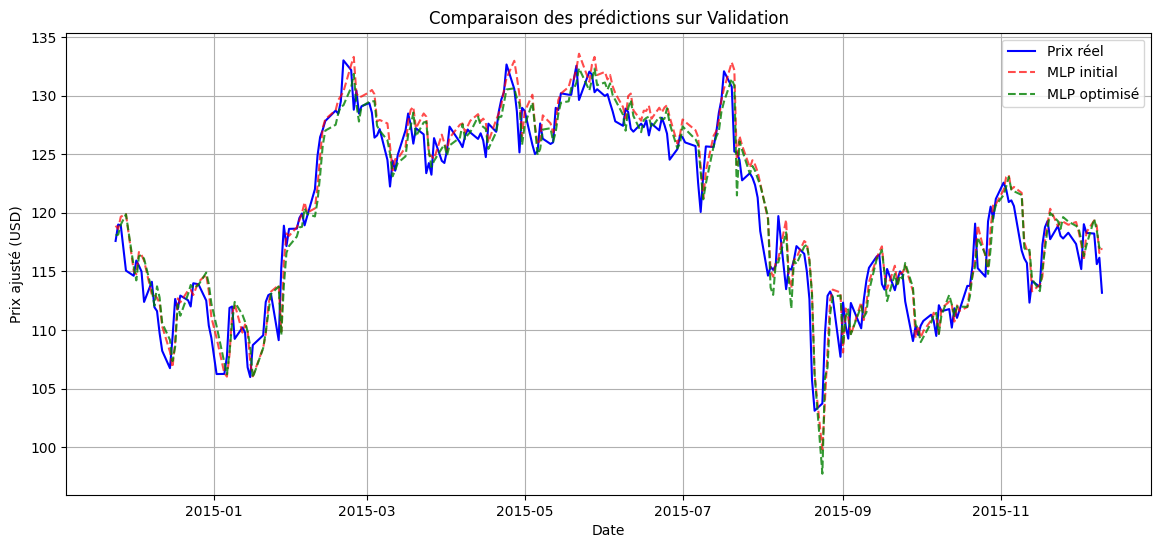

In [30]:
# Dates de validation
val_dates = data["date"].iloc[train_end:val_end]

plt.figure(figsize=(14, 6))

plt.plot(
    val_dates,
    y_val,
    label="Prix réel",
    color="blue"
)

plt.plot(
    val_dates,
    y_pred_val,
    label="MLP initial",
    linestyle="--",
    color="red",
    alpha=0.7
)

plt.plot(
    val_dates,
    y_pred_val_optimized,
    label="MLP optimisé",
    linestyle="--",
    color="green",
    alpha=0.8
)

plt.title("Comparaison des prédictions sur Validation")
plt.xlabel("Date")
plt.ylabel("Prix ajusté (USD)")
plt.legend()
plt.grid(True)

plt.show()

## 12. Régularisation du réseau MLP

Afin de réduire le surapprentissage et d'améliorer la généralisation,
plusieurs techniques de régularisation sont appliquées :

- Dropout : désactivation aléatoire de neurones pendant l'entraînement.
- L2 (Weight Decay) : pénalisation des poids du modèle.
- Early Stopping : arrêt de l'entraînement lorsque la perte
  de validation ne s'améliore plus.

Les performances seront comparées avec celles du MLP initial
et du MLP optimisé par GridSearchCV.

In [31]:
import torch
import torch.nn as nn

class RegularizedMLP(nn.Module):

    def __init__(self, dropout_rate=0.2):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(5, 64),
            nn.ReLU(),
            nn.Dropout(dropout_rate),

            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(dropout_rate),

            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x)


# Reproductibilité
torch.manual_seed(42)

# Initialiser le modèle régularisé
regularized_model = RegularizedMLP(
    dropout_rate=0.2
).to(device)

# Fonction de perte
criterion_reg = nn.MSELoss()

# Optimiseur Adam avec régularisation L2
optimizer_reg = torch.optim.Adam(
    regularized_model.parameters(),
    lr=0.0005,
    weight_decay=0.0001
)

print(regularized_model)

print("\nLearning rate :", optimizer_reg.param_groups[0]["lr"])
print("Weight decay :", optimizer_reg.param_groups[0]["weight_decay"])

RegularizedMLP(
  (network): Sequential(
    (0): Linear(in_features=5, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)

Learning rate : 0.0005
Weight decay : 0.0001


In [35]:
torch.manual_seed(42)

regularized_model = RegularizedMLP(
    dropout_rate=0.2
).to(device)

criterion_reg = nn.MSELoss()

optimizer_reg = torch.optim.Adam(
    regularized_model.parameters(),
    lr=0.0005,
    weight_decay=0.0001
)

print("Modèle initialisé avec succès")

Modèle initialisé avec succès


In [36]:
import copy

max_epochs = 150
patience = 15
min_delta = 0.0001

train_losses_reg = []
val_losses_reg = []

best_val_loss = float("inf")
best_epoch_reg = 0
best_weights = None
patience_counter = 0

for epoch in range(max_epochs):

    # Entraînement
    regularized_model.train()
    running_train_loss = 0.0

    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer_reg.zero_grad()

        predictions = regularized_model(X_batch)
        loss = criterion_reg(predictions, y_batch)

        loss.backward()
        optimizer_reg.step()

        running_train_loss += loss.item() * X_batch.size(0)

    train_loss = running_train_loss / len(train_dataset)
    train_losses_reg.append(train_loss)

    # Validation
    regularized_model.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            predictions = regularized_model(X_batch)
            loss = criterion_reg(predictions, y_batch)

            running_val_loss += loss.item() * X_batch.size(0)

    val_loss = running_val_loss / len(val_dataset)
    val_losses_reg.append(val_loss)

    # Early Stopping
    if val_loss < best_val_loss - min_delta:
        best_val_loss = val_loss
        best_epoch_reg = epoch + 1
        best_weights = copy.deepcopy(
            regularized_model.state_dict()
        )
        patience_counter = 0
    else:
        patience_counter += 1

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch+1}/{max_epochs} | "
            f"Train Loss: {train_loss:.6f} | "
            f"Val Loss: {val_loss:.6f}"
        )

    if patience_counter >= patience:
        print(f"Early Stopping à l'époque {epoch+1}")
        break

# Restaurer le meilleur modèle
regularized_model.load_state_dict(best_weights)
regularized_model.eval()

print("\nMeilleure époque :", best_epoch_reg)
print("Meilleure Validation Loss :", best_val_loss)
print("Époques exécutées :", len(train_losses_reg))

Epoch 10/150 | Train Loss: 0.040538 | Val Loss: 0.021229
Epoch 20/150 | Train Loss: 0.032938 | Val Loss: 0.012722
Epoch 30/150 | Train Loss: 0.031213 | Val Loss: 0.016852
Epoch 40/150 | Train Loss: 0.031318 | Val Loss: 0.016794
Epoch 50/150 | Train Loss: 0.026369 | Val Loss: 0.012353
Epoch 60/150 | Train Loss: 0.026259 | Val Loss: 0.047463
Early Stopping à l'époque 63

Meilleure époque : 48
Meilleure Validation Loss : 0.010367366513519577
Époques exécutées : 63


In [37]:
# Évaluer le modèle régularisé
regularized_model.eval()

with torch.no_grad():
    predictions_reg = regularized_model(
        X_val_tensor.to(device)
    ).cpu().numpy()

# Reconvertir les prédictions en USD
y_pred_val_reg = scaler_y.inverse_transform(
    predictions_reg
).flatten()

# Comparaison sur Validation
final_comparison = pd.DataFrame({
    "MLP Initial": evaluate_regression(y_val, y_pred_val),
    "MLP Optimisé": evaluate_regression(
        y_val, y_pred_val_optimized
    ),
    "MLP Régularisé": evaluate_regression(
        y_val, y_pred_val_reg
    ),
    "Modèle Naïf": evaluate_regression(
        y_val, X_val["close"]
    )
}).T

display(final_comparison.round(4))

,MAE,MSE,RMSE,R2
MLP Initial,1.7126,4.8568,2.2038,0.9110
MLP Optimisé,1.7122,4.8587,2.2043,0.9109
MLP Régularisé,1.6255,4.4714,2.1146,0.9180
Modèle Naïf,1.4899,3.8281,1.9566,0.9298


In [38]:
# Évaluation finale du MLP régularisé sur Test

regularized_model.eval()

with torch.no_grad():
    predictions_test_reg = regularized_model(
        X_test_tensor.to(device)
    ).cpu().numpy()

# Reconvertir les prédictions en USD
y_pred_test_reg = scaler_y.inverse_transform(
    predictions_test_reg
).flatten()

# Comparaison des modèles sur Test
final_test_results = pd.DataFrame({
    "MLP Initial": evaluate_regression(
        y_test, y_pred_test
    ),
    "MLP Régularisé": evaluate_regression(
        y_test, y_pred_test_reg
    ),
    "Modèle Naïf": evaluate_regression(
        y_test, X_test["close"]
    )
}).T

display(final_test_results.round(4))

,MAE,MSE,RMSE,R2
MLP Initial,1.1337,2.4211,1.5560,0.9569
MLP Régularisé,1.1831,2.6688,1.6337,0.9525
Modèle Naïf,1.0635,2.2629,1.5043,0.9597


## 13. Comparaison finale des modèles sur Test

Cette étape présente les prédictions du MLP initial,
du MLP régularisé et du modèle naïf sur les données
de test.

L'objectif est de comparer visuellement leur capacité
à suivre les variations du prix de clôture réel.

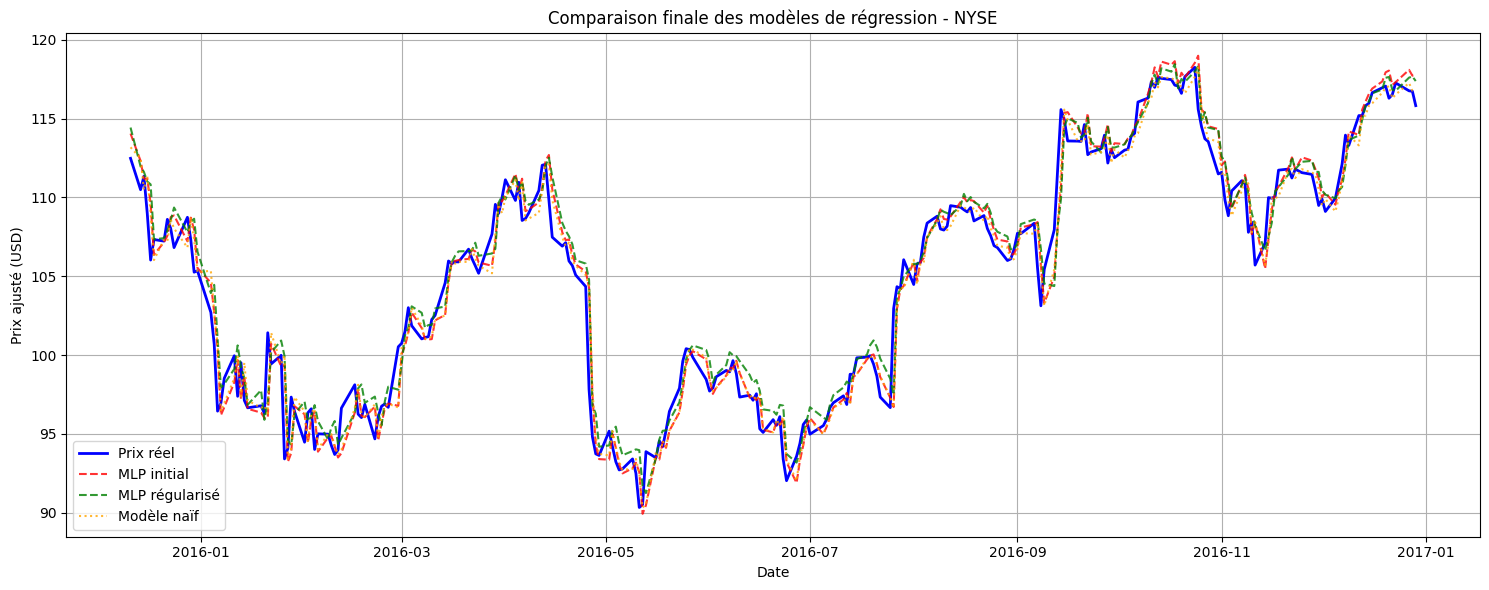

In [39]:
# Dates de l'ensemble Test
test_dates = data["date"].iloc[val_end:]

plt.figure(figsize=(15, 6))

# Prix réels
plt.plot(
    test_dates,
    y_test,
    label="Prix réel",
    color="blue",
    linewidth=2
)

# MLP initial
plt.plot(
    test_dates,
    y_pred_test,
    label="MLP initial",
    color="red",
    linestyle="--",
    alpha=0.8
)

# MLP régularisé
plt.plot(
    test_dates,
    y_pred_test_reg,
    label="MLP régularisé",
    color="green",
    linestyle="--",
    alpha=0.8
)

# Modèle naïf
plt.plot(
    test_dates,
    X_test["close"],
    label="Modèle naïf",
    color="orange",
    linestyle=":",
    alpha=0.8
)

plt.xlabel("Date")
plt.ylabel("Prix ajusté (USD)")
plt.title("Comparaison finale des modèles de régression - NYSE")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()